<a href="https://colab.research.google.com/github/UadrianSP/am-turma5/blob/main/Redes_Neurais_Aula1027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline Conector de Drive Pre-Load de Dados [Credits]

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pickle
with open('/content/drive/MyDrive/am-t5/credit.pkl', 'rb') as f:
  X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

Provedor de Testes [25%]

In [6]:
X_credit_treinamento.shape, y_credit_treinamento.shape

((1500, 3), (1500,))

Provedor de Treino [75%]

In [7]:
X_credit_teste.shape, y_credit_teste.shape

((500, 3), (500,))

 # Pipeline | Redes Neurais [Credit Data]

In [8]:
parametros = {'activation': ['relu', 'logistic', 'tanh'],
              'solver': ['adam', 'sgd'],
              'batch_size': [10, 56]}


In [9]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [11]:
grid_search = GridSearchCV(estimator=MLPClassifier(),param_grid=parametros)
grid_search.fit(X_credit_treinamento, y_credit_treinamento)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay

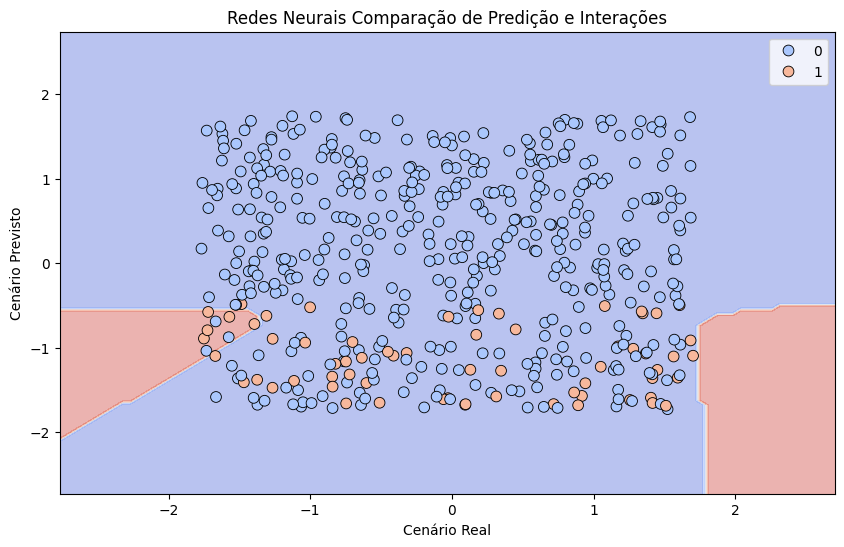

In [16]:

x_2d = X_credit_teste[:, :2]
rna_2d = MLPClassifier(**grid_search.best_params_, max_iter=1000, random_state=42)
rna_2d.fit(x_2d, y_credit_teste)

fig, ax = plt.subplots(figsize=(10, 6))

DecisionBoundaryDisplay.from_estimator(
    rna_2d,
    x_2d,
    cmap="coolwarm",
    alpha=0.4,
    ax=ax,
    response_method="predict"
)

sns.scatterplot(
    x=x_2d[:, 0],
    y=x_2d[:, 1],
    hue=y_credit_teste,
    palette="coolwarm",
    edgecolor="black",
    s=60,
    ax=ax
)
plt.title("Redes Neurais Comparação de Predição e Interações")
plt.xlabel("Cenário Real")
plt.ylabel("Cenário Previsto")
plt.show()